# Adsorptive Desulfurization Sorbents: Capacity Modeling
## 3. Modeling

Ridge regression, lasso and XGBoost were fit to `zeolite_features.csv` (n=16, 9 candidate features) and `ac_features.csv` (n=20, 14 features) and evaluated by leave-one-material-out cross-validation. For the zeolite table this is equivalent to leave-one-out cross-validation, since no material repeats. In the activated-carbon table, each of the 10 materials appears twice (DBT and DMDBT), so each material is held out together with both of its rows. Regularization strength for ridge and lasso was selected by nested cross-validation, and every model was compared with a mean baseline and a group-mean baseline.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

pd.set_option('display.width', 200)
np.random.seed(0)

## Evaluation function

One prediction is generated for each left-out material, collected across all folds and scored once at the end, rather than averaged per fold, because per-fold R² is not meaningful with folds this small.

In [2]:
def evaluate(model_fn, X, y, groups):
    logo = LeaveOneGroupOut()
    preds = np.zeros(len(y))
    for train_idx, test_idx in logo.split(X, y, groups):
        model = model_fn()
        model.fit(X.iloc[train_idx], y.iloc[train_idx])
        preds[test_idx] = model.predict(X.iloc[test_idx])
    mae = mean_absolute_error(y, preds)
    rmse = mean_squared_error(y, preds) ** 0.5
    r2 = r2_score(y, preds)
    return preds, {'MAE': mae, 'RMSE': rmse, 'R2': r2}

def baseline_mean(model_fn, X, y, groups):
    # predicts the training-fold mean for every held-out row
    logo = LeaveOneGroupOut()
    preds = np.zeros(len(y))
    for train_idx, test_idx in logo.split(X, y, groups):
        preds[test_idx] = y.iloc[train_idx].mean()
    mae = mean_absolute_error(y, preds)
    rmse = mean_squared_error(y, preds) ** 0.5
    r2 = r2_score(y, preds)
    return preds, {'MAE': mae, 'RMSE': rmse, 'R2': r2}

## Selecting the regularization strength (alpha)

The diagnostic plots in this notebook (alpha sweep, bias and variance, learning curves) and the full-table coefficients use an alpha selected by leave-one-material-out cross-validated MAE on the whole table. The reported metrics use nested cross-validation instead: within each outer training fold, alpha was chosen by an inner leave-one-material-out cross-validation, so the held-out material never influences the choice of alpha. Scikit-learn's `RidgeCV` and `LassoCV` were not used because their default cross-validation is row-based, which would let a material's DBT row help train a model that is then tested on its DMDBT row.

In [3]:
def cv_mae_at_alpha(model_class, alpha, X, y, groups, **kwargs):
    logo = LeaveOneGroupOut()
    preds = np.zeros(len(y))
    for train_idx, test_idx in logo.split(X, y, groups):
        model = make_pipeline(StandardScaler(), model_class(alpha=alpha, **kwargs))
        model.fit(X.iloc[train_idx], y.iloc[train_idx])
        preds[test_idx] = model.predict(X.iloc[test_idx])
    return mean_absolute_error(y, preds)

def plot_alpha_sweep(X, y, groups, baseline_mae, title, save_path):
    alphas = np.logspace(-2, 3, 40)
    mae_ridge = [cv_mae_at_alpha(Ridge, a, X, y, groups) for a in alphas]
    mae_lasso = [cv_mae_at_alpha(Lasso, a, X, y, groups, max_iter=20000) for a in alphas]
    best_ridge_alpha = alphas[int(np.argmin(mae_ridge))]
    best_lasso_alpha = alphas[int(np.argmin(mae_lasso))]

    fig, ax = plt.subplots(figsize=(6,4))
    ax.plot(alphas, mae_ridge, label='ridge', marker='o', markersize=3)
    ax.plot(alphas, mae_lasso, label='lasso', marker='s', markersize=3)
    ax.axhline(baseline_mae, color='gray', linestyle=':', label='mean baseline')
    ax.axvline(best_ridge_alpha, color='C0', linestyle='--', linewidth=1)
    ax.axvline(best_lasso_alpha, color='C1', linestyle='--', linewidth=1)
    ax.set_xscale('log')
    ax.set_xlabel('alpha')
    ax.set_ylabel('leave-one-material-out CV MAE')
    ax.set_title(title)
    ax.legend()
    plt.tight_layout()
    plt.savefig(save_path, dpi=120)
    plt.show()
    return best_ridge_alpha, best_lasso_alpha, alphas, mae_ridge

## Bias and variance: training error vs. cross-validated error

Ridge regression is shown as the representative case. At each alpha, the model was fit on each training fold and scored on that fold (training error) and on the held-out material (cross-validated error, identical to the curve above). A large gap between the two indicates that the model fits its training data far better than it predicts new materials, i.e. high variance. As alpha increases, the model is more constrained: training error rises and cross-validated error falls until the two converge.

In [4]:
def train_and_cv_mae_at_alpha(alpha, X, y, groups):
    logo = LeaveOneGroupOut()
    cv_preds = np.zeros(len(y))
    train_errs = []
    for train_idx, test_idx in logo.split(X, y, groups):
        model = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
        model.fit(X.iloc[train_idx], y.iloc[train_idx])
        cv_preds[test_idx] = model.predict(X.iloc[test_idx])
        train_pred = model.predict(X.iloc[train_idx])
        train_errs.append(mean_absolute_error(y.iloc[train_idx], train_pred))
    return np.mean(train_errs), mean_absolute_error(y, cv_preds)

def plot_bias_variance(alphas, X, y, groups, chosen_alpha, title, save_path):
    train_maes, cv_maes = zip(*[train_and_cv_mae_at_alpha(a, X, y, groups) for a in alphas])
    fig, ax = plt.subplots(figsize=(6,4))
    ax.plot(alphas, train_maes, label='training MAE', marker='o', markersize=3)
    ax.plot(alphas, cv_maes, label='CV MAE', marker='s', markersize=3)
    ax.axvline(chosen_alpha, color='gray', linestyle='--', linewidth=1, label='chosen alpha')
    ax.set_xscale('log')
    ax.set_xlabel('alpha')
    ax.set_ylabel('MAE')
    ax.set_title(title)
    ax.legend()
    plt.tight_layout()
    plt.savefig(save_path, dpi=120)
    plt.show()

## Learning curves: error vs. training set size

Ridge regression is shown at its selected alpha. For each training-set size, that many materials were sampled at random 40 times, the model was fit on them and scored on the remaining materials as a validation set, and the curve shows the average over the 40 draws. The curve indicates whether additional materials of this kind would be expected to improve performance.

In [5]:
def learning_curve(alpha, X, y, groups, sizes, n_repeats=40, seed=0):
    unique_materials = groups.unique()
    rng = np.random.default_rng(seed)
    rows = []
    for size in sizes:
        train_maes, val_maes = [], []
        for rep in range(n_repeats):
            perm = rng.permutation(unique_materials)
            train_materials = set(perm[:size])
            val_materials = set(perm[size:])
            train_mask = groups.isin(train_materials).values
            val_mask = groups.isin(val_materials).values
            model = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
            model.fit(X[train_mask], y[train_mask])
            train_maes.append(mean_absolute_error(y[train_mask], model.predict(X[train_mask])))
            val_maes.append(mean_absolute_error(y[val_mask], model.predict(X[val_mask])))
        rows.append((size, np.mean(train_maes), np.mean(val_maes)))
    return pd.DataFrame(rows, columns=['train_size', 'train_MAE', 'val_MAE'])

def plot_learning_curve(lc_df, title, save_path):
    fig, ax = plt.subplots(figsize=(6,4))
    ax.plot(lc_df['train_size'], lc_df['train_MAE'], label='training MAE', marker='o')
    ax.plot(lc_df['train_size'], lc_df['val_MAE'], label='validation MAE', marker='s')
    ax.set_xlabel('training set size (materials)')
    ax.set_ylabel('MAE')
    ax.set_title(title)
    ax.legend()
    plt.tight_layout()
    plt.savefig(save_path, dpi=120)
    plt.show()

## Capacity vs. each feature: actual and predicted

The actual and predicted capacities are plotted against every continuous feature. Compound indicator columns are omitted, as they are better read from the results table than from a scatter plot.

In [6]:
def plot_capacity_vs_features(X, y, preds, feature_cols, title, save_path, ncols=3):
    nrows = -(-len(feature_cols) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.5*ncols, 3.5*nrows))
    axes = np.array(axes).reshape(-1)
    for i, feat in enumerate(feature_cols):
        ax = axes[i]
        ax.scatter(X[feat], y, label='actual', marker='x', color='black', s=40)
        for name, marker in [('ridge','o'), ('lasso','s'), ('xgboost','^')]:
            ax.scatter(X[feat], preds[name], label=name, marker=marker, alpha=0.6, s=25)
        ax.set_xlabel(feat)
        ax.set_ylabel('capacity_mgS_g')
        if i == 0:
            ax.legend(fontsize=8)
    for j in range(len(feature_cols), len(axes)):
        axes[j].axis('off')
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(save_path, dpi=120)
    plt.show()

## Comparing feature sets

Ridge and lasso use nested cross-validation (alpha chosen inside each training fold); XGBoost uses fixed hyperparameters. Two baselines are reported: the mean baseline, which predicts the training-fold mean, and a group-mean baseline, which predicts the training-fold mean of rows in the same group (zeolites: Y or SAY, monometallic or bimetallic; activated carbons: sulfur compound). The group-mean baseline is the more relevant comparison because models can score well simply by recovering group differences. Comparing feature sets is itself a selection step on the same data, so at this sample size small differences between sets are within noise.

In [7]:
ALPHAS = np.logspace(-2, 3, 40)

def score(preds, y):
    return {'MAE': mean_absolute_error(y, preds),
            'RMSE': mean_squared_error(y, preds) ** 0.5,
            'R2': r2_score(y, preds)}

def baseline_group_mean(y, groups, strata):
    # predicts the mean of the training-fold rows that share the held-out row's stratum
    preds = np.zeros(len(y))
    for train_idx, test_idx in LeaveOneGroupOut().split(y, y, groups):
        for i in test_idx:
            same = [j for j in train_idx if strata.iloc[j] == strata.iloc[i]]
            preds[i] = y.iloc[same].mean() if same else y.iloc[train_idx].mean()
    return preds

def nested_preds(model_class, X, y, groups, alphas=ALPHAS, **kwargs):
    # alpha is chosen inside each outer training fold by an inner leave-one-material-out CV,
    # so the held-out material never influences the choice of alpha
    preds = np.zeros(len(y))
    for train_idx, test_idx in LeaveOneGroupOut().split(X, y, groups):
        Xtr = X.iloc[train_idx].reset_index(drop=True)
        ytr = y.iloc[train_idx].reset_index(drop=True)
        gtr = groups.iloc[train_idx].reset_index(drop=True)
        inner = [cv_mae_at_alpha(model_class, a, Xtr, ytr, gtr, **kwargs) for a in alphas]
        best_alpha = alphas[int(np.argmin(inner))]
        model = make_pipeline(StandardScaler(), model_class(alpha=best_alpha, **kwargs))
        model.fit(Xtr, ytr)
        preds[test_idx] = model.predict(X.iloc[test_idx])
    return preds

def xgb_model():
    return XGBRegressor(n_estimators=100, max_depth=2, learning_rate=0.1,
                         reg_lambda=5.0, subsample=0.8, random_state=0)

def all_model_preds(X, y, groups):
    return {
        'ridge': nested_preds(Ridge, X, y, groups),
        'lasso': nested_preds(Lasso, X, y, groups, max_iter=20000),
        'xgboost': evaluate(xgb_model, X, y, groups)[0],
    }

def compare_feature_sets(feature_sets, X_all, y, groups, strata=None):
    rows = []
    _, base = baseline_mean(None, X_all, y, groups)
    rows.append({'feature set': '(none)', 'model': 'mean baseline', 'n_features': 0, **base})
    if strata is not None:
        rows.append({'feature set': '(none)', 'model': 'group-mean baseline', 'n_features': 0,
                     **score(baseline_group_mean(y, groups, strata), y)})
    for set_name, cols in feature_sets.items():
        for model_name, p in all_model_preds(X_all[cols], y, groups).items():
            rows.append({'feature set': set_name, 'model': model_name, 'n_features': len(cols), **score(p, y)})
    return pd.DataFrame(rows).round(2)

## Part A: Zeolite table (n=16)

In [8]:
zeo = pd.read_csv('../data/zeolite_features.csv')
X_zeo = zeo.drop(columns=['material', 'capacity_mgS_g'])
y_zeo = zeo['capacity_mgS_g']
groups_zeo = zeo['material']  # no repeats, equivalent to LOOCV
X_zeo.shape

(16, 9)

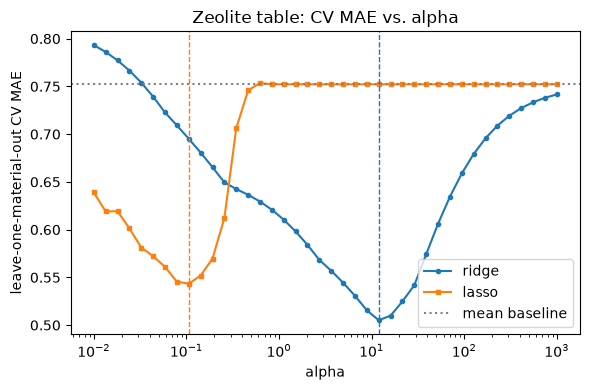

chosen ridge alpha: 11.9
chosen lasso alpha: 0.106


In [9]:
_, baseline_zeo = baseline_mean(None, X_zeo, y_zeo, groups_zeo)
best_ridge_alpha_zeo, best_lasso_alpha_zeo, alphas_zeo, _ = plot_alpha_sweep(
    X_zeo, y_zeo, groups_zeo, baseline_zeo['MAE'],
    'Zeolite table: CV MAE vs. alpha', '../reports/zeolite_alpha_sweep.png')
print(f'chosen ridge alpha: {best_ridge_alpha_zeo:.3g}')
print(f'chosen lasso alpha: {best_lasso_alpha_zeo:.3g}')

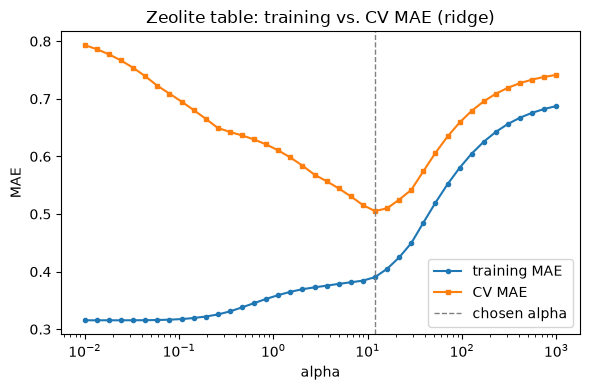

In [10]:
plot_bias_variance(alphas_zeo, X_zeo, y_zeo, groups_zeo, best_ridge_alpha_zeo,
                    'Zeolite table: training vs. CV MAE (ridge)', '../reports/zeolite_bias_variance.png')

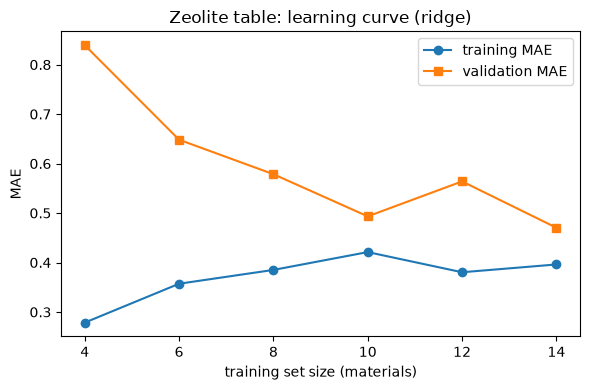

,train_size,train_MAE,val_MAE
0,4,0.278519,0.839286
1,6,0.357147,0.648222
2,8,0.385058,0.578531
3,10,0.421111,0.493314
4,12,0.380350,0.563974
5,14,0.396102,0.470317


In [11]:
lc_zeo = learning_curve(best_ridge_alpha_zeo, X_zeo, y_zeo, groups_zeo, sizes=[4,6,8,10,12,14])
plot_learning_curve(lc_zeo, 'Zeolite table: learning curve (ridge)', '../reports/zeolite_learning_curve.png')
lc_zeo

In [12]:
def ridge_zeo():
    return make_pipeline(StandardScaler(), Ridge(alpha=best_ridge_alpha_zeo))

def lasso_zeo():
    return make_pipeline(StandardScaler(), Lasso(alpha=best_lasso_alpha_zeo, max_iter=20000))

def xgb_zeo():
    return XGBRegressor(n_estimators=100, max_depth=2, learning_rate=0.1,
                         reg_lambda=5.0, subsample=0.8, random_state=0)

strata_zeo = pd.Series(np.where(X_zeo['compound_BT'] == 1, 'Y', 'SAY')) + np.where(
    X_zeo['Cu_wt_pct'] > 0, '_bimetallic', '_monometallic')
results_zeo = {}
preds_zeo = {}
_, results_zeo['mean baseline'] = baseline_mean(None, X_zeo, y_zeo, groups_zeo)
p_gm = baseline_group_mean(y_zeo, groups_zeo, strata_zeo)
results_zeo['group-mean baseline'] = score(p_gm, y_zeo)
preds_zeo = all_model_preds(X_zeo, y_zeo, groups_zeo)
for name, p in preds_zeo.items():
    results_zeo[name] = score(p, y_zeo)

pd.DataFrame(results_zeo).T

,MAE,RMSE,R2
mean baseline,0.752167,1.051261,-0.137778
group-mean baseline,0.555833,0.870804,0.219313
ridge,0.488865,0.711430,0.478925
lasso,0.611238,0.783845,0.367447
xgboost,0.605599,0.957147,0.056823


Under nested cross-validation, the mean baseline had an MAE of 0.75 and the group-mean baseline 0.56. With the full 9-feature set, ridge (MAE 0.49, R² 0.48) beat the group-mean baseline modestly, whereas lasso (0.61) and XGBoost (0.61) did not. Beating the mean baseline alone is therefore not informative here, because most of the signal is the difference between groups.

In [13]:
zeo_orig_cols = ['RE_f_electrons', 'RE_wt_pct', 'Cu_wt_pct', 'Vmicro_cm3g', 'Vmeso_cm3g', 'compound_BT', 'compound_DBT']
zeo_full_cols = list(X_zeo.columns)
compare_feature_sets({'original (7)': zeo_orig_cols, 'with 4f features (9)': zeo_full_cols}, X_zeo, y_zeo, groups_zeo, strata_zeo)

,feature set,model,n_features,MAE,RMSE,R2
0,(none),mean baseline,0,0.75,1.05,-0.14
1,(none),group-mean baseline,0,0.56,0.87,0.22
2,original (7),ridge,7,0.64,0.87,0.22
3,original (7),lasso,7,0.62,0.84,0.27
4,original (7),xgboost,7,0.72,1.02,-0.07
5,with 4f features (9),ridge,9,0.49,0.71,0.48
6,with 4f features (9),lasso,9,0.61,0.78,0.37
7,with 4f features (9),xgboost,9,0.61,0.96,0.06


Adding the two derived 4f columns lowered ridge MAE from 0.64 to 0.49 and XGBoost MAE from 0.72 to 0.61, and left lasso essentially unchanged (0.62 to 0.61). With the original seven columns, no model beat the group-mean baseline (0.56). The derived columns were designed after the Ce peak was observed in the same data and are recodings of rare-earth identity, so this is weak, exploratory evidence that the Ce peak is usable, not confirmation.

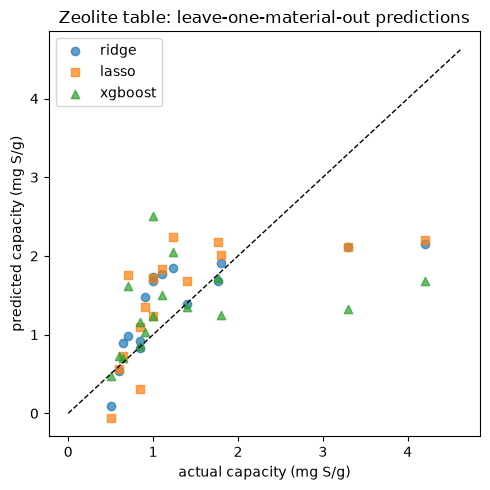

In [14]:
fig, ax = plt.subplots(figsize=(5,5))
for name, marker in [('ridge','o'), ('lasso','s'), ('xgboost','^')]:
    ax.scatter(y_zeo, preds_zeo[name], label=name, marker=marker, alpha=0.7)
lims = [0, y_zeo.max()*1.1]
ax.plot(lims, lims, 'k--', linewidth=1)
ax.set_xlabel('actual capacity (mg S/g)')
ax.set_ylabel('predicted capacity (mg S/g)')
ax.set_title('Zeolite table: leave-one-material-out predictions')
ax.legend()
plt.tight_layout()
plt.savefig('../reports/zeolite_loo_predictions.png', dpi=120)
plt.show()

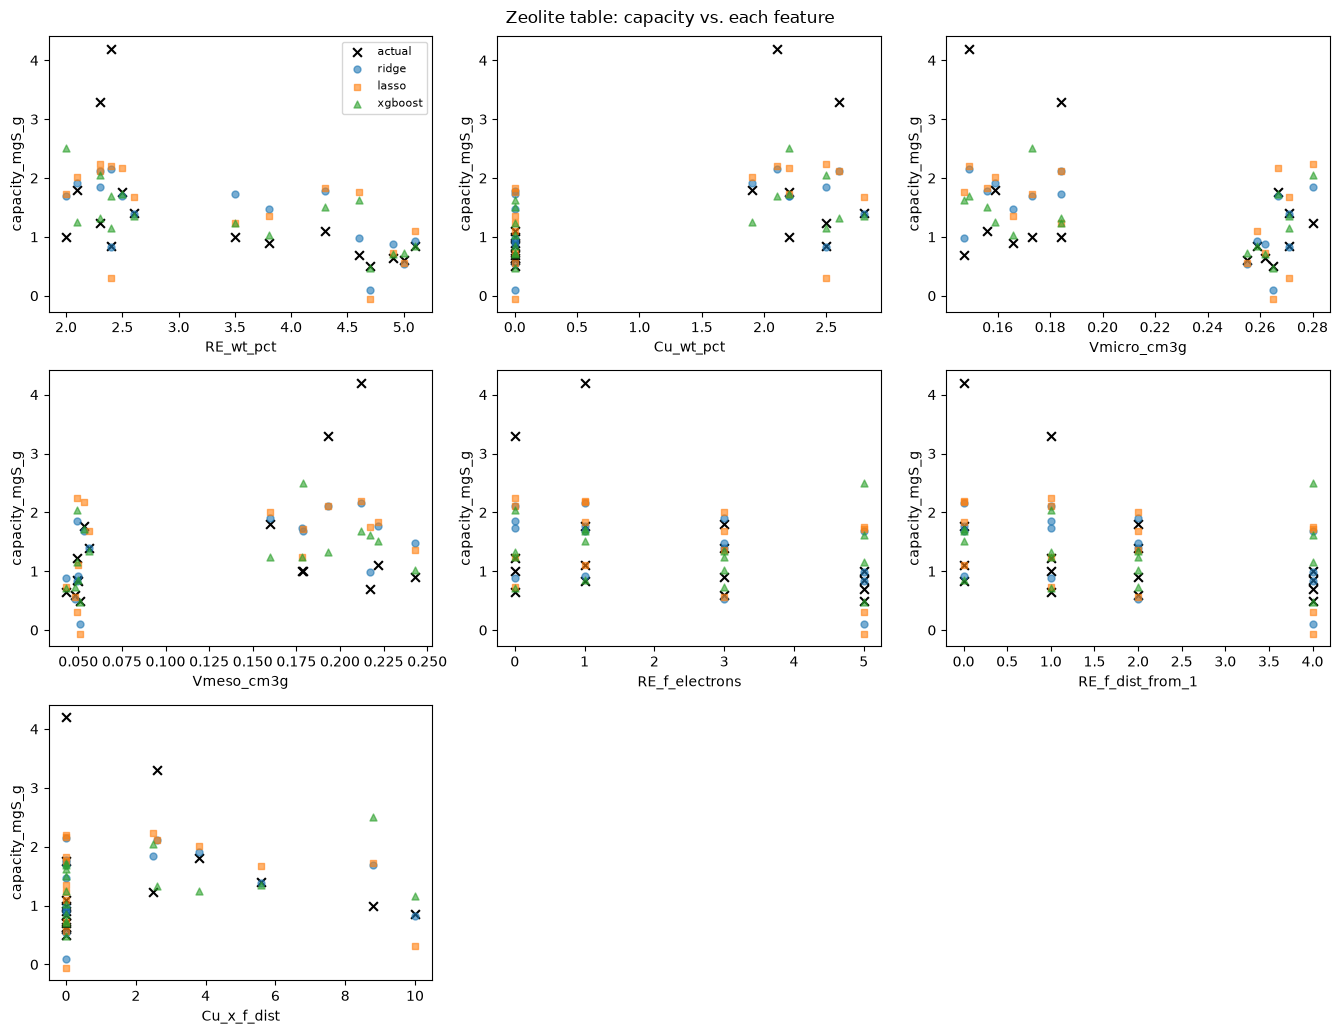

In [15]:
zeo_plot_features = ['RE_wt_pct', 'Cu_wt_pct', 'Vmicro_cm3g', 'Vmeso_cm3g', 'RE_f_electrons', 'RE_f_dist_from_1', 'Cu_x_f_dist']
plot_capacity_vs_features(X_zeo, y_zeo, preds_zeo, zeo_plot_features,
                           'Zeolite table: capacity vs. each feature', '../reports/zeolite_capacity_vs_features.png')

## Part B: Activated carbon table (n=20)

In [16]:
ac = pd.read_csv('../data/ac_features.csv')
X_ac = ac.drop(columns=['material', 'capacity_mgS_g'])
y_ac = ac['capacity_mgS_g']
groups_ac = ac['material']  # all 10 materials contribute 2 rows each
X_ac.shape

(20, 14)

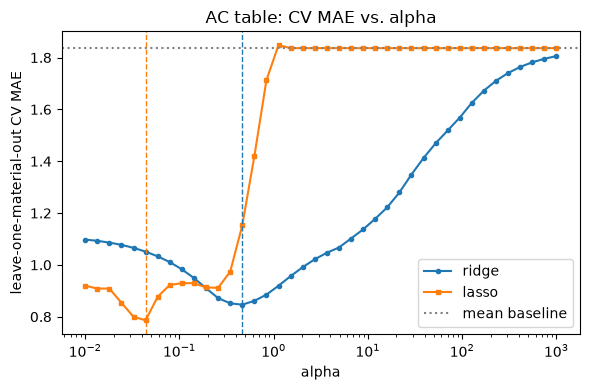

chosen ridge alpha: 0.464
chosen lasso alpha: 0.0438


In [17]:
_, baseline_ac = baseline_mean(None, X_ac, y_ac, groups_ac)
best_ridge_alpha_ac, best_lasso_alpha_ac, alphas_ac, _ = plot_alpha_sweep(
    X_ac, y_ac, groups_ac, baseline_ac['MAE'],
    'AC table: CV MAE vs. alpha', '../reports/ac_alpha_sweep.png')
print(f'chosen ridge alpha: {best_ridge_alpha_ac:.3g}')
print(f'chosen lasso alpha: {best_lasso_alpha_ac:.3g}')

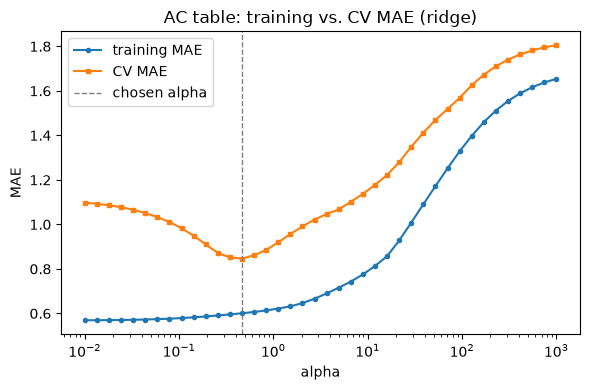

In [18]:
plot_bias_variance(alphas_ac, X_ac, y_ac, groups_ac, best_ridge_alpha_ac,
                    'AC table: training vs. CV MAE (ridge)', '../reports/ac_bias_variance.png')

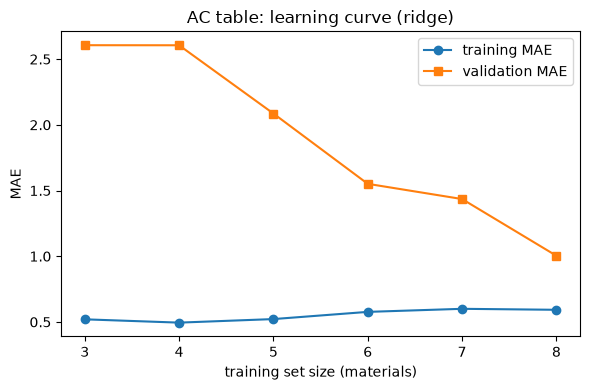

,train_size,train_MAE,val_MAE
0,3,0.520100,2.606059
1,4,0.494966,2.605558
2,5,0.521940,2.086028
3,6,0.576721,1.551137
4,7,0.600061,1.435328
5,8,0.592607,1.003707


In [19]:
lc_ac = learning_curve(best_ridge_alpha_ac, X_ac, y_ac, groups_ac, sizes=[3,4,5,6,7,8])
plot_learning_curve(lc_ac, 'AC table: learning curve (ridge)', '../reports/ac_learning_curve.png')
lc_ac

In [20]:
def ridge_ac():
    return make_pipeline(StandardScaler(), Ridge(alpha=best_ridge_alpha_ac))

def lasso_ac():
    return make_pipeline(StandardScaler(), Lasso(alpha=best_lasso_alpha_ac, max_iter=20000))

def xgb_ac():
    return XGBRegressor(n_estimators=100, max_depth=2, learning_rate=0.1,
                         reg_lambda=5.0, subsample=0.8, random_state=0)

strata_ac = X_ac['is_DMDBT'].map({0: 'DBT', 1: 'DMDBT'})
results_ac = {}
_, results_ac['mean baseline'] = baseline_mean(None, X_ac, y_ac, groups_ac)
results_ac['compound-mean baseline'] = score(baseline_group_mean(y_ac, groups_ac, strata_ac), y_ac)
preds_ac = all_model_preds(X_ac, y_ac, groups_ac)
for name, p in preds_ac.items():
    results_ac[name] = score(p, y_ac)

pd.DataFrame(results_ac).T

,MAE,RMSE,R2
mean baseline,1.836389,2.253628,-0.152326
compound-mean baseline,1.503889,2.034187,0.061158
ridge,0.931631,1.289799,0.622554
lasso,0.898381,1.146378,0.701828
xgboost,1.121918,1.487421,0.498029


Under nested cross-validation, the global mean baseline had an MAE of 1.84 and the compound-mean baseline (training-fold mean for the same sulfur compound) 1.50. With ID/IG included, lasso reached an MAE of 0.90 (R² 0.70), ridge 0.93 (R² 0.62) and XGBoost 1.12 (R² 0.50).

In [21]:
ac_orig_cols = [c for c in X_ac.columns if c != 'ID_IG_ratio']
ac_full_cols = list(X_ac.columns)
ac_sets = {'without ID/IG (13)': ac_orig_cols, 'with ID/IG (14)': ac_full_cols,
           'ID/IG + DMDBT only (2)': ['ID_IG_ratio', 'is_DMDBT']}
compare_feature_sets(ac_sets, X_ac, y_ac, groups_ac, strata_ac)

,feature set,model,n_features,MAE,RMSE,R2
0,(none),mean baseline,0,1.84,2.25,-0.15
1,(none),group-mean baseline,0,1.50,2.03,0.06
2,without ID/IG (13),ridge,13,1.90,2.28,-0.18
3,without ID/IG (13),lasso,13,1.83,2.31,-0.21
4,without ID/IG (13),xgboost,13,1.18,1.55,0.46
5,with ID/IG (14),ridge,14,0.93,1.29,0.62
6,with ID/IG (14),lasso,14,0.90,1.15,0.70
7,with ID/IG (14),xgboost,14,1.12,1.49,0.50
8,ID/IG + DMDBT only (2),ridge,2,1.31,1.68,0.36
9,ID/IG + DMDBT only (2),lasso,2,1.30,1.66,0.38


Without ID/IG, ridge (1.90) and lasso (1.83) did no better than the global mean baseline (1.84) and were worse than the compound-mean baseline (1.50), while XGBoost (1.18) improved on the compound-mean baseline. Adding ID/IG reduced the ridge MAE from 1.90 to 0.93 and the lasso MAE from 1.83 to 0.90, but the XGBoost MAE only from 1.18 to 1.12. A two-feature model using only ID/IG and the DMDBT indicator reached 1.31 with ridge and 1.30 with lasso, so much of the gain comes from those two features, with the other 12 features giving a further reduction (ridge 1.31 to 0.93, lasso 1.30 to 0.90). For XGBoost the two-feature model (1.65) was worse than the model without ID/IG (1.18) and the full set (1.12). As a check on the dependence on a single material, the comparison was repeated without CAC, the material with the lowest capacity and lowest ID/IG.

In [22]:
keep = (groups_ac != 'CAC').values
compare_feature_sets(ac_sets, X_ac[keep].reset_index(drop=True), y_ac[keep].reset_index(drop=True),
                     groups_ac[keep].reset_index(drop=True), strata_ac[keep].reset_index(drop=True))

,feature set,model,n_features,MAE,RMSE,R2
0,(none),mean baseline,0,1.64,1.99,-0.14
1,(none),group-mean baseline,0,1.24,1.65,0.22
2,without ID/IG (13),ridge,13,2.07,2.54,-0.85
3,without ID/IG (13),lasso,13,2.23,2.81,-1.25
4,without ID/IG (13),xgboost,13,1.15,1.28,0.53
5,with ID/IG (14),ridge,14,1.47,2.04,-0.19
6,with ID/IG (14),lasso,14,1.01,1.46,0.39
7,with ID/IG (14),xgboost,14,1.05,1.24,0.56
8,ID/IG + DMDBT only (2),ridge,2,1.37,1.73,0.15
9,ID/IG + DMDBT only (2),lasso,2,1.45,1.80,0.07


Without CAC (9 materials; mean baseline 1.64, compound-mean baseline 1.24), ridge with ID/IG reached 1.47 and no longer beat the compound-mean baseline, while lasso (1.01) and XGBoost (1.05) still did. XGBoost without ID/IG reached 1.15, so its result did not depend on ID/IG, whereas the lasso MAE without ID/IG was 2.23. The row-level correlation between ID/IG and capacity also fell from 0.60 to 0.36 (see `01_eda.ipynb`). The ridge result with ID/IG is therefore driven partly by CAC, the commercial carbon at the extreme of both capacity and ID/IG, and with 9 materials the lasso result should be regarded as suggestive, not established.

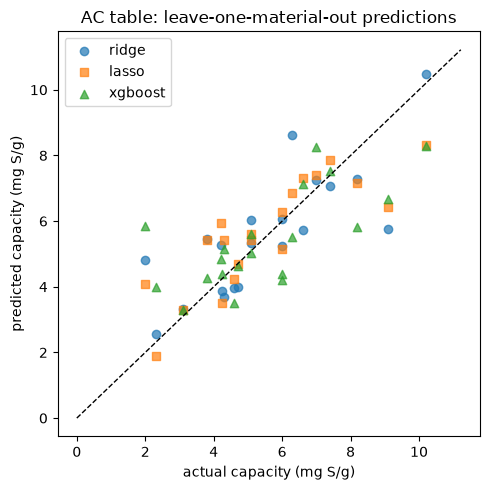

In [23]:
fig, ax = plt.subplots(figsize=(5,5))
for name, marker in [('ridge','o'), ('lasso','s'), ('xgboost','^')]:
    ax.scatter(y_ac, preds_ac[name], label=name, marker=marker, alpha=0.7)
lims = [0, y_ac.max()*1.1]
ax.plot(lims, lims, 'k--', linewidth=1)
ax.set_xlabel('actual capacity (mg S/g)')
ax.set_ylabel('predicted capacity (mg S/g)')
ax.set_title('AC table: leave-one-material-out predictions')
ax.legend()
plt.tight_layout()
plt.savefig('../reports/ac_loo_predictions.png', dpi=120)
plt.show()

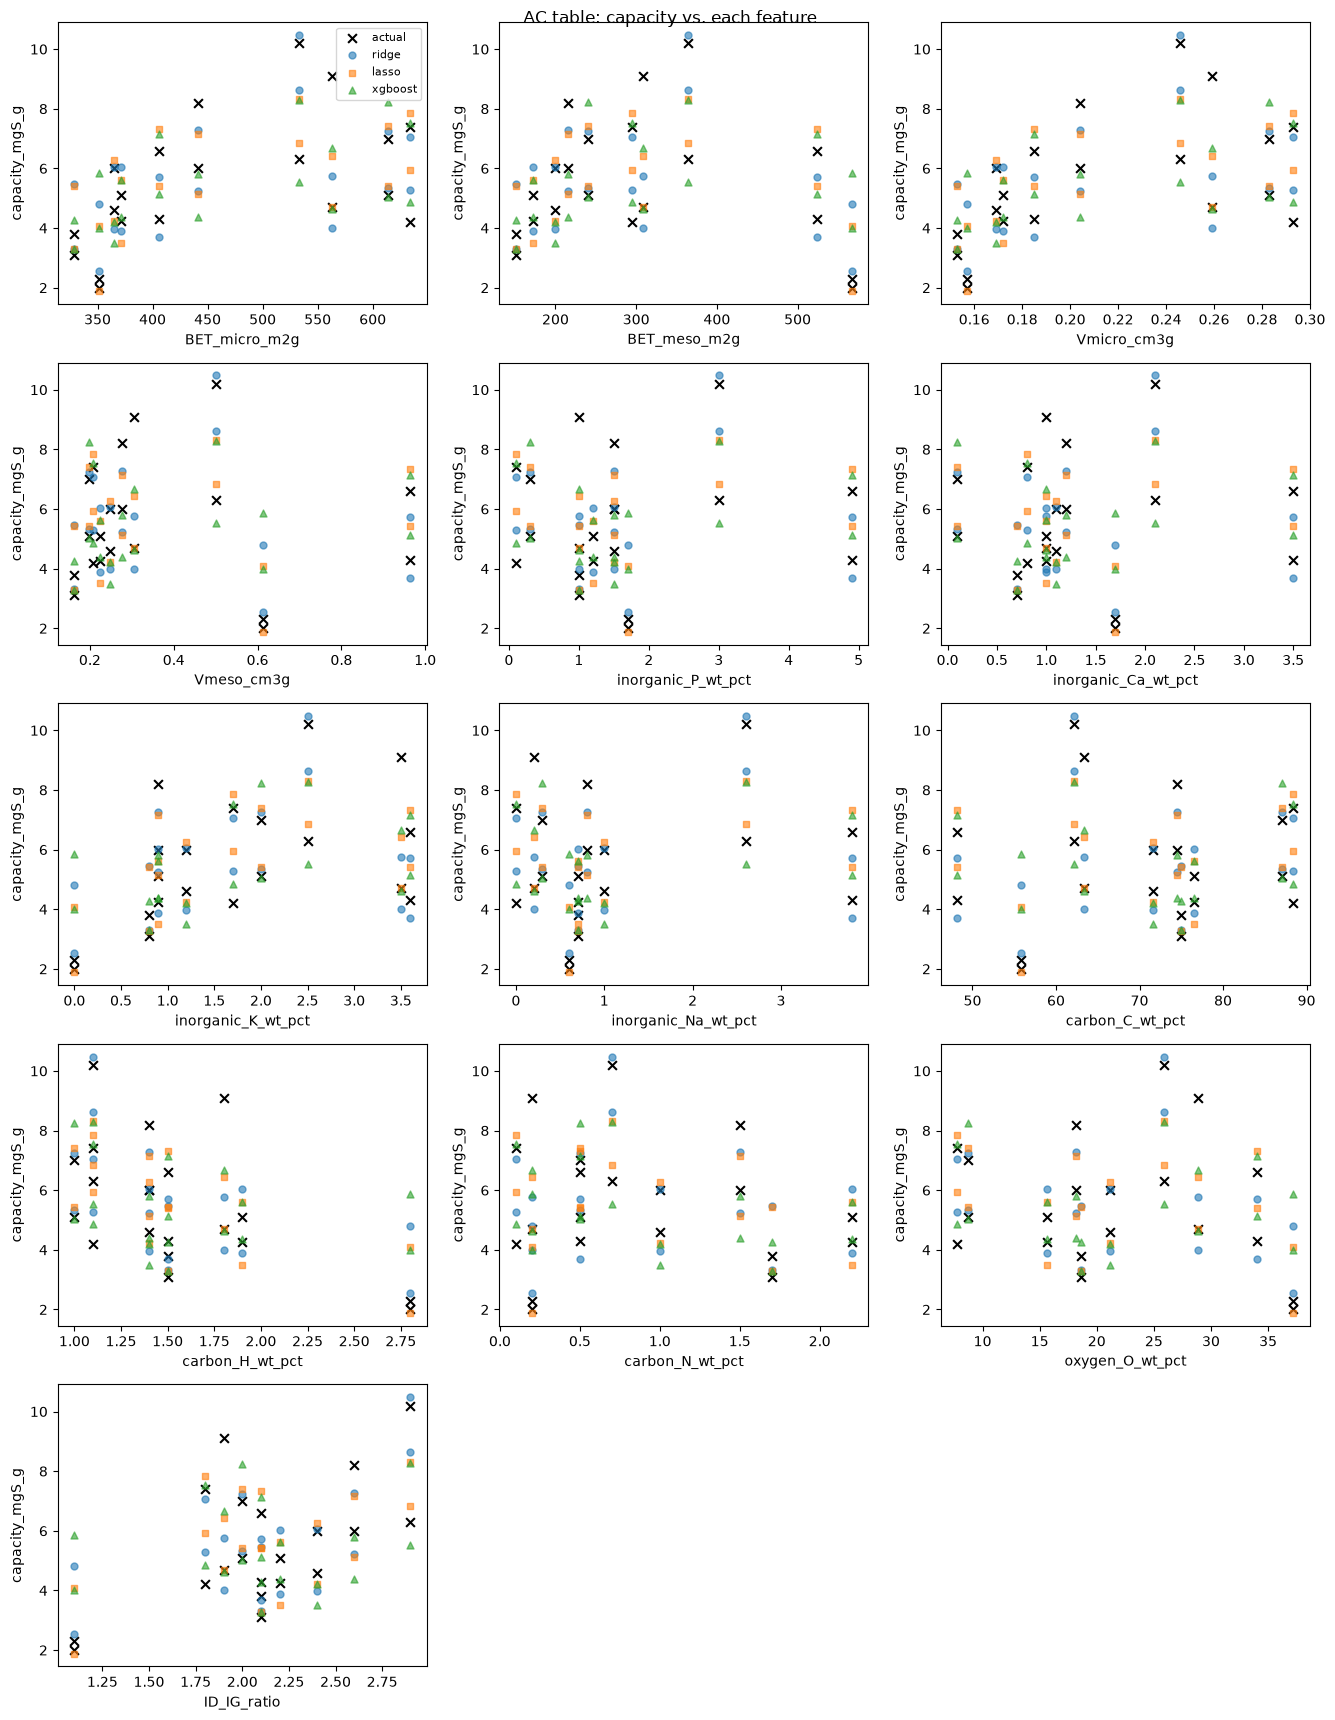

In [24]:
ac_plot_features = ['BET_micro_m2g', 'BET_meso_m2g', 'Vmicro_cm3g', 'Vmeso_cm3g', 'inorganic_P_wt_pct', 'inorganic_Ca_wt_pct',
                     'inorganic_K_wt_pct', 'inorganic_Na_wt_pct', 'carbon_C_wt_pct', 'carbon_H_wt_pct', 'carbon_N_wt_pct', 'oxygen_O_wt_pct', 'ID_IG_ratio']
plot_capacity_vs_features(X_ac, y_ac, preds_ac, ac_plot_features,
                           'AC table: capacity vs. each feature', '../reports/ac_capacity_vs_features.png')

## Coefficients and feature importance

Ridge models were fit on the full table (not on a cross-validation fold) using the selected alpha. The coefficients are shown for inspection only and are not validated effect sizes at this sample size.

In [25]:
ridge_full_zeo = ridge_zeo()
ridge_full_zeo.fit(X_zeo, y_zeo)
coefs_zeo = pd.Series(ridge_full_zeo.named_steps['ridge'].coef_, index=X_zeo.columns).sort_values(key=abs, ascending=False)
print("Zeolite ridge coefficients (standardized):")
print(coefs_zeo)
print(f"\nalpha: {best_ridge_alpha_zeo:.3g}")

Zeolite ridge coefficients (standardized):
Cu_wt_pct           0.272194
RE_wt_pct          -0.177005
RE_f_dist_from_1   -0.172705
RE_f_electrons     -0.108088
Vmicro_cm3g        -0.102367
Cu_x_f_dist        -0.087384
Vmeso_cm3g          0.073828
compound_BT        -0.066854
compound_DBT        0.066854
dtype: float64

alpha: 11.9


In [26]:
ridge_full_ac = ridge_ac()
ridge_full_ac.fit(X_ac, y_ac)
coefs_ac = pd.Series(ridge_full_ac.named_steps['ridge'].coef_, index=X_ac.columns).sort_values(key=abs, ascending=False)
print("AC ridge coefficients (standardized):")
print(coefs_ac)
print(f"\nalpha: {best_ridge_alpha_ac:.3g}")

AC ridge coefficients (standardized):
ID_IG_ratio            1.380924
is_DMDBT               1.004195
inorganic_Na_wt_pct   -0.659454
BET_micro_m2g          0.605060
Vmicro_cm3g            0.585213
inorganic_Ca_wt_pct    0.255823
oxygen_O_wt_pct        0.224212
Vmeso_cm3g             0.216626
inorganic_P_wt_pct     0.177963
BET_meso_m2g          -0.173469
carbon_C_wt_pct       -0.169273
inorganic_K_wt_pct     0.151284
carbon_H_wt_pct        0.133403
carbon_N_wt_pct        0.021474
dtype: float64

alpha: 0.464


## XGBoost feature importance

XGBoost was also fit on the full table, for the same inspection-only purpose as the ridge coefficients above.

In [27]:
xgb_full_zeo = xgb_zeo()
xgb_full_zeo.fit(X_zeo, y_zeo)
imp_zeo = pd.Series(xgb_full_zeo.feature_importances_, index=X_zeo.columns).sort_values(ascending=False)
print("Zeolite XGBoost feature importance:")
print(imp_zeo)

Zeolite XGBoost feature importance:
Vmeso_cm3g          0.274822
RE_wt_pct           0.190188
RE_f_dist_from_1    0.112627
Cu_x_f_dist         0.110210
Cu_wt_pct           0.109828
RE_f_electrons      0.103146
Vmicro_cm3g         0.099179
compound_BT         0.000000
compound_DBT        0.000000
dtype: float32


In [28]:
xgb_full_ac = xgb_ac()
xgb_full_ac.fit(X_ac, y_ac)
imp_ac = pd.Series(xgb_full_ac.feature_importances_, index=X_ac.columns).sort_values(ascending=False)
print("AC XGBoost feature importance:")
print(imp_ac)

AC XGBoost feature importance:
BET_micro_m2g          0.320936
is_DMDBT               0.156987
inorganic_K_wt_pct     0.141047
ID_IG_ratio            0.112764
Vmeso_cm3g             0.070178
carbon_N_wt_pct        0.055386
BET_meso_m2g           0.040232
carbon_C_wt_pct        0.038157
inorganic_Na_wt_pct    0.029873
carbon_H_wt_pct        0.025526
inorganic_Ca_wt_pct    0.008914
Vmicro_cm3g            0.000000
inorganic_P_wt_pct     0.000000
oxygen_O_wt_pct        0.000000
dtype: float32


## Error analysis

Leave-one-material-out predictions from all three models, sorted by the largest absolute error any of them made on that row.

In [29]:
err_zeo = pd.DataFrame({
    'material': zeo['material'],
    'actual': y_zeo,
    'ridge_pred': preds_zeo['ridge'].round(2),
    'lasso_pred': preds_zeo['lasso'].round(2),
    'xgboost_pred': preds_zeo['xgboost'].round(2),
})
err_zeo['worst_abs_error'] = err_zeo[['ridge_pred','lasso_pred','xgboost_pred']].sub(err_zeo['actual'], axis=0).abs().max(axis=1)
err_zeo.sort_values('worst_abs_error', ascending=False).head(5)

,material,actual,ridge_pred,lasso_pred,xgboost_pred,worst_abs_error
15,CuCeSAY,4.20,2.16,2.20,1.69,2.51
12,CuLaSAY,3.30,2.11,2.12,1.32,1.98
14,CuSmSAY,1.00,1.69,1.72,2.51,1.51
10,SmSAY,0.70,0.98,1.76,1.62,1.06
4,CuLaY,1.23,1.85,2.24,2.05,1.01


In [30]:
err_ac = pd.DataFrame({
    'material': ac['material'],
    'actual': y_ac,
    'ridge_pred': preds_ac['ridge'].round(2),
    'lasso_pred': preds_ac['lasso'].round(2),
    'xgboost_pred': preds_ac['xgboost'].round(2),
})
err_ac['worst_abs_error'] = err_ac[['ridge_pred','lasso_pred','xgboost_pred']].sub(err_ac['actual'], axis=0).abs().max(axis=1)
err_ac.sort_values('worst_abs_error', ascending=False).head(5)

,material,actual,ridge_pred,lasso_pred,xgboost_pred,worst_abs_error
7,CAC,2.0,4.81,4.08,5.86,3.86
1,MisAC,9.1,5.76,6.43,6.67,3.34
15,FWAC35,8.2,7.28,7.16,5.81,2.39
16,FWAC25,6.3,8.63,6.85,5.53,2.33
17,FWAC25,10.2,10.48,8.31,8.28,1.92


## Limitations

- The tables contain 16 and 20 rows. Every metric above comes from a single pass of leave-one-material-out predictions, without repeated resampling, so the numbers carry no error bars and a few materials predicted differently would shift them substantially.
- XGBoost hyperparameters (depth, number of estimators, regularization) were fixed and not tuned, since there is not enough data to tune them without fitting noise.
- Reported metrics for ridge and lasso use nested cross-validation. The alpha sweep, bias-variance plot, learning curves and full-table coefficients use an alpha selected on the whole table, so they are diagnostics, not unbiased performance estimates. The alpha grid is fixed (40 log-spaced points from 0.01 to 1000), and the true optimum may lie between grid points.
- Coefficients and feature importances come from a full-data fit and are shown for inspection, not from the cross-validation folds. They should not be read as confirmed effect sizes.
- Comparing feature sets (with and without the derived 4f columns, with and without ID/IG) is a further selection step on the same data, so small differences between sets are within noise at this sample size. The derived 4f columns were designed after the Ce peak was observed in the same rows.
- The zeolite table has two exactly complementary compound indicators (`compound_BT`, `compound_DBT`), so its nine columns contain eight independent features.
- The learning curves use random subsets of materials rather than a fixed held-out set, because there is not enough data to reserve one permanently. Each point averages 40 random splits, but with only 16 or 10 materials in total, the variance between splits remains large.
- XGBoost results depend on the library version. Re-running the same code and random seed with older libraries (Python 3.8, pandas 1.3.5, scikit-learn 1.0.2, XGBoost 1.6.2) left the ridge and lasso results unchanged but moved XGBoost MAEs by up to 0.19 mg S/g (for example, activated carbons without CAC, using only ID/IG and the DMDBT indicator: 1.15 against 1.34) and changed the ranking of its feature importances. Differences between XGBoost configurations of that size should not be interpreted.